Cell 1: setup, data, helpers

In [ ]:
import os, json, time, random, platform, shutil
import numpy as np, pandas as pd, tensorflow as tf, sklearn, scipy
import matplotlib.pyplot as plt
from IPython.display import display
from tensorflow import keras
from tensorflow.keras import layers
from scipy.ndimage import gaussian_filter, rotate
from sklearn.metrics import roc_auc_score, roc_curve
from google.colab import drive

drive.mount("/content/drive")
SRC = "/content/drive/MyDrive/uc1_jalon2"      # données et journal du jalon 2
DOSSIER = "/content/drive/MyDrive/uc1_jalon3"  # tout le jalon 3 est sauvegardé ici
os.makedirs(DOSSIER, exist_ok=True)
for f in ["uc1_domaineA.npz", "uc1_domaineB.npz", "journal.jsonl"]:
    if not os.path.exists(f"{DOSSIER}/{f}") and os.path.exists(f"{SRC}/{f}"):
        shutil.copy(f"{SRC}/{f}", f"{DOSSIER}/{f}")
os.chdir(DOSSIER)
print(os.listdir("."))

SEED = 0
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)
L_MAX, N_CLASSES, EMPTY = 5, 11, 10
IMG_H, IMG_W = 32, 128
NOMS_POS = ["unités", "dizaines", "centaines", "milliers", "dizaines de milliers"]
SPLITS = ["train", "val", "test"]
print("Python", platform.python_version(), "| TF", tf.__version__, "| sklearn", sklearn.__version__,
      "| NumPy", np.__version__, "| SciPy", scipy.__version__)
print("GPU :", tf.config.list_physical_devices("GPU"))

def charger(chemin):
    d = np.load(chemin, allow_pickle=True)
    X = {s: (d[f"X_{s}"].astype("float32") / 255.0)[..., None] for s in SPLITS}
    M = {}
    for s in SPLITS:
        M[f"montant_{s}"] = d[f"montant_{s}"].astype(str)
        M[f"altere_{s}"] = d[f"altere_{s}"]
        M[f"type_{s}"] = d[f"type_alteration_{s}"]
    return X, M

XA, A = charger("uc1_domaineA.npz")
XB, B = charger("uc1_domaineB.npz")

# ---------- encodage et lecture ----------
def vers_positions(montants):
    Y = np.full((len(montants), L_MAX), EMPTY, dtype=int)
    for i, m in enumerate(montants):
        for k, ch in enumerate(str(m)[::-1]):
            Y[i, k] = int(ch)
    return Y

def en_dict(Y):
    return {f"pos{k}": Y[:, k] for k in range(L_MAX)}

def predire_probs(model, X):
    P = model.predict(X, batch_size=512, verbose=0)
    return np.stack([P[f"pos{k}"] for k in range(L_MAX)], axis=1)      # (N, 5, 11)

def lire_probs(probs):
    cls = probs.argmax(2)
    conf = probs.max(2).prod(1)
    lus = np.array(["".join(str(c) for c in ligne[::-1] if c != EMPTY) for ligne in cls])
    return lus, conf

def lire_positions(model, X):
    return lire_probs(predire_probs(model, X))

def taux_automatisation(lus, montants, conf, seuil=0.99):
    ordre = np.argsort(-conf)
    ok = (lus[ordre] == montants[ordre]).astype(float)
    cum = np.cumsum(ok) / np.arange(1, len(ok) + 1)
    bons = np.where(cum >= seuil)[0]
    return float((bons.max() + 1) / len(ok)) if len(bons) else 0.0

def evaluer_lecture(montants, lus, conf):
    return dict(exact=round(float(np.mean(lus == montants)), 4),
                auto=round(taux_automatisation(lus, montants, conf), 4))

def exactitude_par_position(probs, Y):
    return [float(np.mean(probs[:, k].argmax(1) == Y[:, k])) for k in range(L_MAX)]

def exactitude_par_longueur(lus, montants):
    lg = np.char.str_len(montants); out = {}
    for n in range(1, L_MAX + 1):
        sel = lg == n
        if sel.any():
            out[n] = (round(float(np.mean(lus[sel] == montants[sel])), 3), int(sel.sum()))
    return out

# ---------- journal et historiques ----------
def journaliser(jalon, nom, **infos):
    with open("journal.jsonl", "a") as f:
        f.write(json.dumps({"jalon": jalon, "nom": nom, "t": time.strftime("%F %T"), **infos},
                           default=float) + "\n")

def journaliser_une_fois(jalon, nom, **infos):
    if os.path.exists("journal.jsonl"):
        for ligne in open("journal.jsonl"):
            if ligne.strip():
                e = json.loads(ligne)
                if e["jalon"] == jalon and e["nom"] == nom:
                    return
    journaliser(jalon, nom, **infos)

def sauver_histoire(cle, H, fichier="histories_jalon3.json"):
    d = json.load(open(fichier)) if os.path.exists(fichier) else {}
    d[cle] = H
    json.dump(d, open(fichier, "w"), default=float)

def lire_histoire(cle, fichier="histories_jalon3.json"):
    return json.load(open(fichier))[cle]

# ---------- cibles ----------
YA = {s: vers_positions(A["montant_" + s]) for s in SPLITS}
YB = {s: vers_positions(B["montant_" + s]) for s in SPLITS}
ALT = {s: A["altere_" + s] for s in SPLITS}
for nom, X in [("A", XA), ("B", XB)]:
    print(nom, {s: X[s].shape[0] for s in SPLITS})

Mounted at /content/drive
['uc1_domaineA.npz', 'uc1_domaineB.npz', 'lecteur_A_depart.keras', 'histories_jalon3.json', 'journal.jsonl']
Python 3.13.16 | TF 2.21.0 | sklearn 1.6.1 | NumPy 2.1.3 | SciPy 1.16.3
GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
A {'train': 15000, 'val': 3000, 'test': 5000}
B {'train': 600, 'val': 400, 'test': 3000}


Cell 2: starter reader (3 blocks, 15 epochs, no augmentation)

In [ ]:
def cnn_lecteur():
    entree = keras.Input((32, 128, 1))
    x = entree
    for filtres in (32, 64, 64):
        x = layers.Conv2D(filtres, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu", name="dense_lecture")(x)
    x = layers.Dropout(0.3)(x)
    sorties = {f"pos{k}": layers.Dense(11, activation="softmax", name=f"pos{k}")(x)
               for k in range(L_MAX)}
    return keras.Model(entree, sorties, name="cnn_lecteur")

PERTES = {f"pos{k}": "sparse_categorical_crossentropy" for k in range(L_MAX)}

if os.path.exists("lecteur_A_depart.keras"):
    lecteur_A = keras.models.load_model("lecteur_A_depart.keras")
    print("rechargé depuis Drive")
else:
    keras.utils.set_random_seed(SEED)
    lecteur_A = cnn_lecteur()
    lecteur_A.compile(keras.optimizers.Adam(1e-3), loss=PERTES)
    h = lecteur_A.fit(XA["train"], en_dict(YA["train"]), epochs=15, batch_size=128,
                      validation_data=(XA["val"], en_dict(YA["val"])), verbose=2)
    lecteur_A.save("lecteur_A_depart.keras")
    sauver_histoire("lecteur_A_depart", h.history)
    print("sauvegardé sur Drive")

Epoch 1/15
118/118 - 26s - 217ms/step - loss: 9.0226 - pos0_loss: 2.3014 - pos1_loss: 2.3370 - pos2_loss: 2.1307 - pos3_loss: 1.5011 - pos4_loss: 0.7455 - val_loss: 7.7392 - val_pos0_loss: 1.9574 - val_pos1_loss: 2.0529 - val_pos2_loss: 1.8162 - val_pos3_loss: 1.2907 - val_pos4_loss: 0.6198
Epoch 2/15
118/118 - 2s - 20ms/step - loss: 7.3512 - pos0_loss: 1.7485 - pos1_loss: 1.9750 - pos2_loss: 1.7756 - pos3_loss: 1.2520 - pos4_loss: 0.5945 - val_loss: 6.1168 - val_pos0_loss: 1.2488 - val_pos1_loss: 1.7263 - val_pos2_loss: 1.4780 - val_pos3_loss: 1.0960 - val_pos4_loss: 0.5629
Epoch 3/15
118/118 - 3s - 23ms/step - loss: 6.1699 - pos0_loss: 1.2549 - pos1_loss: 1.7301 - pos2_loss: 1.5496 - pos3_loss: 1.0903 - pos4_loss: 0.5361 - val_loss: 5.0718 - val_pos0_loss: 0.8734 - val_pos1_loss: 1.4957 - val_pos2_loss: 1.3049 - val_pos3_loss: 0.9079 - val_pos4_loss: 0.4859
Epoch 4/15
118/118 - 5s - 40ms/step - loss: 5.4202 - pos0_loss: 0.9588 - pos1_loss: 1.5578 - pos2_loss: 1.4220 - pos3_loss: 0.99

Cell 3: how far the reader drops on B (task 1, first half)

In [ ]:
res = {}
for dom, X, D, Y in [("A", XA, A, YA), ("B", XB, B, YB)]:
    probs = predire_probs(lecteur_A, X["val"])
    lus, conf = lire_probs(probs)
    res[dom] = evaluer_lecture(D["montant_val"], lus, conf)
    print(f"\n=== Scanner {dom} (validation, {len(lus)} images) ===")
    print(res[dom])
    print("par position :", [round(a, 3) for a in exactitude_par_position(probs, Y["val"])])
    print("par longueur :", exactitude_par_longueur(lus, D["montant_val"]))

# Intervalle de confiance approximatif à 95 % sur B (n = 400)
p, n = res["B"]["exact"], len(B["montant_val"])
print(f"\nB : exact = {p:.3f} ± {1.96 * np.sqrt(p * (1 - p) / n):.3f}")

journaliser_une_fois(3, "lecteur_A_depart_mesure", exact_A_val=res["A"]["exact"], auto_A_val=res["A"]["auto"],
                     exact_B_val=res["B"]["exact"], auto_B_val=res["B"]["auto"],
                     epochs=15, aug=0, remarque="lecteur de départ, avant tout transfert")


=== Scanner A (validation, 3000 images) ===
{'exact': 0.388, 'auto': 0.078}
par position : [0.886, 0.708, 0.671, 0.764, 0.877]
par longueur : {1: (0.964, 137), 2: (0.754, 467), 3: (0.514, 985), 4: (0.176, 907), 5: (0.028, 504)}

=== Scanner B (validation, 400 images) ===
{'exact': 0.0025, 'auto': 0.0}
par position : [0.47, 0.323, 0.215, 0.087, 0.18]
par longueur : {1: (0.0, 18), 2: (0.0, 54), 3: (0.0, 150), 4: (0.008, 120), 5: (0.0, 58)}

B : exact = 0.003 ± 0.005


Cell 4: characterise the shift (task 1, second half)

It covers intensities, blur, background pattern and rotation. It uses 600 images from each scanner so the comparison is fair.

,A (médiane [5% ; 95%]),B (médiane [5% ; 95%])
fond,0.000 [0.000 ; 0.000],0.176 [0.129 ; 0.220]
encre,0.906 [0.827 ; 0.981],0.741 [0.592 ; 0.894]
contraste,0.906 [0.827 ; 0.981],0.565 [0.431 ; 0.706]
nettete,0.525 [0.484 ; 0.642],0.399 [0.343 ; 0.456]
grain,0.000 [0.000 ; 0.019],0.029 [0.022 ; 0.036]


A | n=285 | angle médian -0.82° | écart-type 2.58° | 5-95 % : -5.35° à +2.72°
B | n=310 | angle médian -0.32° | écart-type 3.95° | 5-95 % : -6.61° à +5.28°


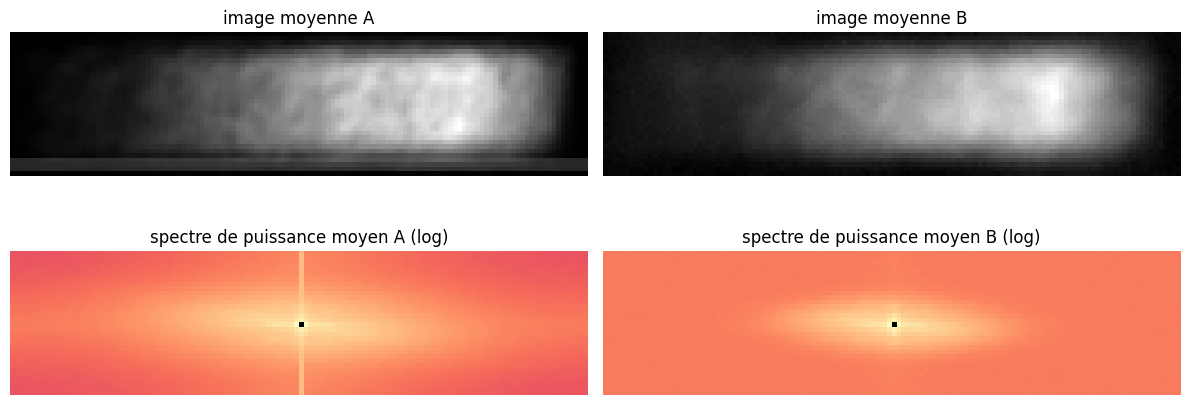

In [ ]:
def caracteriser(X):
    img = X[..., 0]; N = len(img); flat = img.reshape(N, -1)
    fond = np.median(flat, 1); encre = np.percentile(flat, 99, 1)
    gy, gx = np.gradient(img, axis=(1, 2))
    g = np.sqrt(gx ** 2 + gy ** 2).reshape(N, -1)
    return dict(fond=fond, encre=encre, contraste=encre - fond,
                nettete=np.percentile(g, 99, 1) / (encre - fond + 1e-8),   # raideur des bords / contraste
                grain=np.array([np.median(np.abs(s - gaussian_filter(s, 1.0))) for s in img]))

cA, cB = caracteriser(XA["train"][:600]), caracteriser(XB["train"])
fmt = lambda v: f"{np.median(v):.3f}  [{np.percentile(v, 5):.3f} ; {np.percentile(v, 95):.3f}]"
display(pd.DataFrame({"A (médiane [5% ; 95%])": {k: fmt(v) for k, v in cA.items()},
                      "B (médiane [5% ; 95%])": {k: fmt(v) for k, v in cB.items()}}))

def angle_ligne(X):
    """Angle (degrés) de l'axe principal de l'encre : proxy de l'inclinaison de la ligne de chiffres."""
    yy, xx = np.mgrid[0:IMG_H, 0:IMG_W]; out = []
    for img in X[..., 0]:
        f, e = np.median(img), np.percentile(img, 99)
        m = img > f + 0.5 * (e - f)
        if m.sum() < 40 or np.ptp(xx[m]) < 60:
            continue
        c = np.cov(xx[m] - xx[m].mean(), yy[m] - yy[m].mean())
        out.append(np.degrees(0.5 * np.arctan2(2 * c[0, 1], c[0, 0] - c[1, 1])))
    return np.array(out)

for nom, X in [("A", XA["train"][:600]), ("B", XB["train"])]:
    a = angle_ligne(X)
    print(f"{nom} | n={len(a)} | angle médian {np.median(a):+.2f}° | écart-type {a.std():.2f}° | "
          f"5-95 % : {np.percentile(a, 5):+.2f}° à {np.percentile(a, 95):+.2f}°")

def spectre_moyen(X):
    img = X[:600, ..., 0]
    img = img - img.mean(axis=(1, 2), keepdims=True)
    P = np.abs(np.fft.fftshift(np.fft.fft2(img), axes=(1, 2))) ** 2
    return np.log10(P.mean(0) + 1e-9)

fig, ax = plt.subplots(2, 2, figsize=(12, 5))
for c, (nom, X) in enumerate([("A", XA["train"]), ("B", XB["train"])]):
    ax[0, c].imshow(X[:600, ..., 0].mean(0), cmap="gray"); ax[0, c].set_title(f"image moyenne {nom}"); ax[0, c].axis("off")
    ax[1, c].imshow(spectre_moyen(X), cmap="magma"); ax[1, c].set_title(f"spectre de puissance moyen {nom} (log)"); ax[1, c].axis("off")
plt.tight_layout(); plt.show()

Cell 5: theory check (parameters, frozen part)

Do the hand calculation first, using your Jalon 2 formulas: convolution = 3·3·c_in·filters + filters, dense = inputs·outputs + outputs. Then run this.

In [ ]:
m = cnn_lecteur()
total = m.count_params()
for l in m.layers:
    if l.count_params():
        print(f"{l.name:18s} {l.count_params():>9,d}")
for l in m.layers:
    if isinstance(l, layers.Conv2D):
        l.trainable = False
entr = sum(int(np.prod(w.shape)) for w in m.trainable_weights)
print(f"\ntotal = {total:,} | entraînables (convolutions gelées) = {entr:,} | gelés = {total - entr:,}")
print(f"part entraînable = {entr / total:.1%} | paramètres entraînables par image étiquetée (600) = {entr / 600:.0f}")

conv2d_3                 320
conv2d_4              18,496
conv2d_5              36,928
dense_lecture        524,416
pos0                   1,419
pos1                   1,419
pos2                   1,419
pos3                   1,419
pos4                   1,419

total = 587,255 | entraînables (convolutions gelées) = 531,511 | gelés = 55,744
part entraînable = 90.5% | paramètres entraînables par image étiquetée (600) = 886


Cell 6: calibrate corrompre (rotation check, needed for task 3)

In [ ]:
def corrompre(X, rng, rot_max=2.0, flou=(0.6, 1.4), fond=(0.09, 0.20), contraste=(0.55, 0.85),
              raies=(0.02, 0.07), lambda_=(10, 30), taches=0.04, bruit=(0.03, 0.07), bruit_flou=0.7):
    N, H, W, _ = X.shape
    out = np.empty_like(X)
    yy, xx = np.mgrid[0:H, 0:W].astype("float32")
    for i in range(N):
        img = rotate(X[i, :, :, 0], rng.uniform(-rot_max, rot_max), reshape=False, order=1, mode="constant", cval=0.0)
        img = gaussian_filter(img, rng.uniform(*flou))
        img = rng.uniform(*fond) + rng.uniform(*contraste) * img
        th, lam, ph = rng.uniform(0.3, 1.2), rng.uniform(*lambda_), rng.uniform(0, 2 * np.pi)
        img = img + rng.uniform(*raies) * np.sin(2 * np.pi * (xx * np.cos(th) + yy * np.sin(th)) / lam + ph)
        t = gaussian_filter(rng.normal(0, 1, (H, W)), 5); img = img + taches * t / (t.std() + 1e-8)
        n = gaussian_filter(rng.normal(0, 1, (H, W)), bruit_flou); n = n / (n.std() + 1e-8)
        img = img + rng.uniform(*bruit) * n
        out[i, :, :, 0] = np.clip(img, 0, 1)
    return out

t0 = time.time()
Xc600 = corrompre(XA["train"][:600], np.random.default_rng(0))
print(f"corruption de 600 images en {time.time() - t0:.0f} s")

cC = caracteriser(Xc600)
display(pd.DataFrame({"A": {k: fmt(v) for k, v in cA.items()},
                      "A corrompue": {k: fmt(v) for k, v in cC.items()},
                      "B": {k: fmt(v) for k, v in cB.items()}}))
for nom, X in [("A", XA["train"][:600]), ("A corrompue (±2°)", Xc600), ("B", XB["train"])]:
    a = angle_ligne(X)
    print(f"{nom:20s} | n={len(a)} | angle médian {np.median(a):+.2f}° | écart-type {a.std():.2f}°")

corruption de 600 images en 1 s


,A,A corrompue,B
fond,0.000 [0.000 ; 0.000],0.178 [0.115 ; 0.240],0.176 [0.129 ; 0.220]
encre,0.906 [0.827 ; 0.981],0.717 [0.553 ; 0.898],0.741 [0.592 ; 0.894]
contraste,0.906 [0.827 ; 0.981],0.531 [0.388 ; 0.699],0.565 [0.431 ; 0.706]
nettete,0.525 [0.484 ; 0.642],0.401 [0.326 ; 0.480],0.399 [0.343 ; 0.456]
grain,0.000 [0.000 ; 0.019],0.023 [0.016 ; 0.030],0.029 [0.022 ; 0.036]


A                    | n=285 | angle médian -0.82° | écart-type 2.58°
A corrompue (±2°)    | n=392 | angle médian -0.74° | écart-type 4.40°
B                    | n=310 | angle médian -0.32° | écart-type 3.95°


Cell 7: task 2, the three strategies (plus “heads only”)

In [ ]:
PERTES = {f"pos{k}": "sparse_categorical_crossentropy" for k in range(L_MAX)}

# Bonus (1 s par ligne) : quelle rotation max colle à la dispersion d'angle de B ?
for r in (0.0, 1.0, 2.0):
    a = angle_ligne(corrompre(XA["train"][:600], np.random.default_rng(0), rot_max=r))
    print(f"rot_max = {r:.0f}° | écart-type de l'angle = {a.std():.2f}° (B : 3.95°)")

rot_max = 0° | écart-type de l'angle = 4.67° (B : 3.95°)
rot_max = 1° | écart-type de l'angle = 4.26° (B : 3.95°)
rot_max = 2° | écart-type de l'angle = 4.40° (B : 3.95°)


In [ ]:
# Lecteur fort du jalon 2, copié dans le dossier du jalon 3
if not os.path.exists("cnn_final_80ep.keras"):
    shutil.copy(f"{SRC}/cnn_final_80ep.keras", "cnn_final_80ep.keras")
BASES = {"depart": keras.models.load_model("lecteur_A_depart.keras"),
         "fort":   keras.models.load_model("cnn_final_80ep.keras")}

def decaler(X, max_px, rng):
    out = np.zeros_like(X); W = X.shape[2]
    for i, d_ in enumerate(rng.integers(-max_px, max_px + 1, len(X))):
        if d_ >= 0: out[i, :, d_:, :] = X[i, :, :W - d_, :]
        else:       out[i, :, :W + d_, :] = X[i, :, -d_:, :]
    return out

for nom, mdl in BASES.items():
    lus, conf = lire_positions(mdl, XA["val"]); ra = evaluer_lecture(A["montant_val"], lus, conf)
    lus, conf = lire_positions(mdl, XB["val"]); rb = evaluer_lecture(B["montant_val"], lus, conf)
    print(f"base {nom:7s} | A val {ra} | B val {rb} | params {mdl.count_params():,}")

def preparer(base, mode, lr, seed):
    keras.utils.set_random_seed(seed)
    m = keras.models.clone_model(base)              # même architecture, poids aléatoires
    if mode != "zero":
        m.set_weights(base.get_weights())           # poids appris sur A
    for l in m.layers:
        if mode == "extraction" and isinstance(l, layers.Conv2D):
            l.trainable = False                     # convolutions gelées
        if mode == "tetes" and l.count_params() and not l.name.startswith("pos"):
            l.trainable = False                     # tout gelé sauf les 5 têtes
    m.compile(keras.optimizers.Adam(lr), loss=PERTES)
    return m

FICHIER_T2 = "resultats_t2.json"

def entrainer_B(base_nom, mode, lr, seed=0, epochs=60, batch=32, aug=0):
    cle = f"{base_nom}_{mode}_lr{lr:g}_s{seed}" + (f"_aug{aug}" if aug else "")
    R = json.load(open(FICHIER_T2)) if os.path.exists(FICHIER_T2) else {}
    if cle in R:
        print("déjà fait :", cle, "| exact val B =", R[cle]["exact_val"]); return R[cle]
    t0 = time.time()
    m = preparer(BASES[base_nom], mode, lr, seed)
    nb_entr = int(sum(np.prod(w.shape) for w in m.trainable_weights))
    rng = np.random.default_rng(seed)
    best, best_w, ep = -1.0, None, 0
    H = {"loss_tr": [], "exact_va": []}
    for e in range(epochs):
        Xe = decaler(XB["train"], aug, rng) if aug else XB["train"]
        h = m.fit(Xe, en_dict(YB["train"]), epochs=1, batch_size=batch, verbose=0)
        lus, _ = lire_positions(m, XB["val"])
        ex = float(np.mean(lus == B["montant_val"]))
        H["loss_tr"].append(h.history["loss"][0]); H["exact_va"].append(ex)
        if ex > best:
            best, best_w, ep = ex, m.get_weights(), e + 1
    m.set_weights(best_w)
    lus, conf = lire_positions(m, XB["val"])
    ev = evaluer_lecture(B["montant_val"], lus, conf)
    res = dict(base=base_nom, mode=mode, lr=lr, seed=seed, epochs=epochs, aug=aug, batch=batch,
               exact_val=ev["exact"], auto_val=ev["auto"], epoque=ep, params_entr=nb_entr,
               exact_val_dernier=H["exact_va"][-1], duree_s=round(time.time() - t0), H=H)
    m.save(f"t2_{cle}.keras")
    R = json.load(open(FICHIER_T2)) if os.path.exists(FICHIER_T2) else {}
    R[cle] = res; json.dump(R, open(FICHIER_T2, "w"), default=float)
    journaliser(3, "t2_" + cle, **{k: v for k, v in res.items() if k != "H"})
    print(f"{cle:34s} | exact val B = {ev['exact']:.3f} | auto = {ev['auto']:.3f} | "
          f"époque {ep} | entraînables {nb_entr:,} | {res['duree_s']} s")
    keras.backend.clear_session()
    return res

CONFIGS_T2 = [("zero", 1e-3), ("tetes", 1e-3), ("extraction", 1e-3),
              ("fine", 1e-3), ("fine", 3e-4), ("fine", 1e-4), ("fine", 3e-5), ("fine", 1e-5)]
for base_nom in ["fort"]:            # ajouter "depart" ensuite pour la ligne de référence
    for mode, lr in CONFIGS_T2:
        entrainer_B(base_nom, mode, lr)

R = json.load(open(FICHIER_T2))
tab = pd.DataFrame([{k: v for k, v in r.items() if k not in ("H", "batch", "aug")} for r in R.values()])
display(tab.sort_values(["base", "exact_val"], ascending=[True, False]).reset_index(drop=True))

base depart  | A val {'exact': 0.388, 'auto': 0.078} | B val {'exact': 0.0025, 'auto': 0.0} | params 587,255


base fort    | A val {'exact': 0.7567, 'auto': 0.344} | B val {'exact': 0.0025, 'auto': 0.0} | params 230,967
fort_zero_lr0.001_s0               | exact val B = 0.048 | auto = 0.013 | époque 24 | entraînables 230,967 | 40 s
fort_tetes_lr0.001_s0              | exact val B = 0.055 | auto = 0.000 | époque 51 | entraînables 7,095 | 26 s
fort_extraction_lr0.001_s0         | exact val B = 0.195 | auto = 0.005 | époque 30 | entraînables 138,295 | 25 s
fort_fine_lr0.001_s0               | exact val B = 0.598 | auto = 0.110 | époque 20 | entraînables 230,967 | 31 s
fort_fine_lr0.0003_s0              | exact val B = 0.598 | auto = 0.168 | époque 48 | entraînables 230,967 | 30 s
fort_fine_lr0.0001_s0              | exact val B = 0.570 | auto = 0.142 | époque 51 | entraînables 230,967 | 31 s
fort_fine_lr3e-05_s0               | exact val B = 0.502 | auto = 0.100 | époque 60 | entraînables 230,967 | 31 s
fort_fine_lr1e-05_s0               | exact val B = 0.265 | auto = 0.048 | époque 60 | entraîna

,base,mode,lr,seed,epochs,exact_val,auto_val,epoque,params_entr,exact_val_dernier,duree_s
0,fort,fine,0.00100,0,60,0.5975,0.1100,20,230967,0.5325,31
1,fort,fine,0.00030,0,60,0.5975,0.1675,48,230967,0.5675,30
2,fort,fine,0.00010,0,60,0.5700,0.1425,51,230967,0.5550,31
3,fort,fine,0.00003,0,60,0.5025,0.1000,60,230967,0.5025,31
4,fort,fine,0.00001,0,60,0.2650,0.0475,60,230967,0.2650,31
5,fort,extraction,0.00100,0,60,0.1950,0.0050,30,138295,0.1825,25
6,fort,tetes,0.00100,0,60,0.0550,0.0000,51,7095,0.0475,26
7,fort,zero,0.00100,0,60,0.0475,0.0125,24,230967,0.0275,40


Cell 8: seeds, starter reference rows, and cost on A

This runs the three plateau learning rates on 3 seeds, adds the starter as a reference row, and measures what fine-tuning costs on scanner A. Everything is saved to Drive and skips finished runs, so the cell takes about 6 to 8 minutes

In [ ]:
# 1) Trois graines pour les lr du plateau (seed 0 déjà fait)
for s in (1, 2):
    for lr in (1e-3, 3e-4, 1e-4):
        entrainer_B("fort", "fine", lr, seed=s)

# 2) Lignes de référence avec le lecteur de départ (graine 0)
for mode, lr in [("zero", 1e-3), ("extraction", 1e-3), ("fine", 3e-4), ("fine", 1e-4)]:
    entrainer_B("depart", mode, lr)

# 3) Synthèse moyenne ± écart-type entre graines
R = json.load(open(FICHIER_T2))
df = pd.DataFrame([{k: v for k, v in r.items() if k != "H"} for r in R.values()])
syn = (df.groupby(["base", "mode", "lr"])
         .agg(n=("seed", "count"), exact_moy=("exact_val", "mean"), exact_std=("exact_val", "std"),
              dernier_moy=("exact_val_dernier", "mean"), auto_moy=("auto_val", "mean"),
              auto_std=("auto_val", "std")).round(3).reset_index())
display(syn.sort_values(["base", "exact_moy"], ascending=[True, False]))

# 4) Coût sur A : le modèle ajusté lit-il encore le scanner A ?
for cle in ["fort_fine_lr0.0003_s0", "fort_fine_lr0.0001_s0"]:
    mdl = keras.models.load_model(f"t2_{cle}.keras")
    lus, conf = lire_positions(mdl, XA["val"])
    print(f"{cle} | A val : {evaluer_lecture(A['montant_val'], lus, conf)} (avant ajustement : exact 0.757, auto 0.344)")

fort_fine_lr0.001_s1               | exact val B = 0.625 | auto = 0.105 | époque 7 | entraînables 230,967 | 31 s
fort_fine_lr0.0003_s1              | exact val B = 0.603 | auto = 0.168 | époque 36 | entraînables 230,967 | 32 s
fort_fine_lr0.0001_s1              | exact val B = 0.578 | auto = 0.150 | époque 59 | entraînables 230,967 | 31 s
fort_fine_lr0.001_s2               | exact val B = 0.595 | auto = 0.122 | époque 26 | entraînables 230,967 | 31 s
fort_fine_lr0.0003_s2              | exact val B = 0.603 | auto = 0.172 | époque 39 | entraînables 230,967 | 31 s
fort_fine_lr0.0001_s2              | exact val B = 0.578 | auto = 0.135 | époque 60 | entraînables 230,967 | 32 s
depart_zero_lr0.001_s0             | exact val B = 0.062 | auto = 0.010 | époque 46 | entraînables 587,255 | 31 s
depart_extraction_lr0.001_s0       | exact val B = 0.190 | auto = 0.005 | époque 12 | entraînables 531,511 | 25 s
depart_fine_lr0.0003_s0            | exact val B = 0.287 | auto = 0.015 | époque 10 | ent

,base,mode,lr,n,exact_moy,exact_std,dernier_moy,auto_moy,auto_std
1,depart,fine,0.00010,1,0.298,NaN,0.282,0.025,NaN
2,depart,fine,0.00030,1,0.288,NaN,0.270,0.015,NaN
0,depart,extraction,0.00100,1,0.190,NaN,0.145,0.005,NaN
3,depart,zero,0.00100,1,0.062,NaN,0.055,0.010,NaN
9,fort,fine,0.00100,3,0.606,0.017,0.541,0.112,0.009
8,fort,fine,0.00030,3,0.601,0.003,0.582,0.169,0.003
7,fort,fine,0.00010,3,0.575,0.004,0.562,0.142,0.007
6,fort,fine,0.00003,1,0.502,NaN,0.502,0.100,NaN
5,fort,fine,0.00001,1,0.265,NaN,0.265,0.048,NaN
4,fort,extraction,0.00100,1,0.195,NaN,0.182,0.005,NaN


fort_fine_lr0.0003_s0 | A val : {'exact': 0.5817, 'auto': 0.141} (avant ajustement : exact 0.757, auto 0.344)
fort_fine_lr0.0001_s0 | A val : {'exact': 0.59, 'auto': 0.1183} (avant ajustement : exact 0.757, auto 0.344)


Cell 9: corrupted copies and the two augmented readers

In [ ]:
ROT_MAX = 2.0
N_COPIES = 3

def corruptions_A():
    fich = [f"corrA_train_c{i}_rot{ROT_MAX:g}.npy" for i in range(N_COPIES)]
    if all(os.path.exists(f) for f in fich):
        return [np.load(f).astype("float32")[..., None] / 255.0 for f in fich]
    rng = np.random.default_rng(SEED + 100)
    copies = []
    for i, f in enumerate(fich):
        t0 = time.time()
        Xc = corrompre(XA["train"], rng, rot_max=ROT_MAX)
        q = np.round(Xc[..., 0] * 255).astype("uint8")       # stockage uint8 (comme les données d'origine)
        np.save(f, q); copies.append(q.astype("float32")[..., None] / 255.0)
        print(f"copie {i} corrompue et sauvegardée en {time.time() - t0:.0f} s")
    return copies

COPIES = corruptions_A()

def decaler_bord(X, max_px, rng):
    """Décalage horizontal ; la zone libérée est remplie avec la colonne du bord (pas de bande noire sur un fond gris)."""
    out = np.empty_like(X); W = X.shape[2]
    for i, d_ in enumerate(rng.integers(-max_px, max_px + 1, len(X))):
        if d_ > 0:
            out[i, :, d_:] = X[i, :, :W - d_]; out[i, :, :d_] = X[i, :, :1]
        elif d_ < 0:
            out[i, :, :W + d_] = X[i, :, -d_:]; out[i, :, W + d_:] = X[i, :, -1:]
        else:
            out[i] = X[i]
    return out

def build_cnn_fort(nom="cnn_aug", filters=(32, 64, 64, 64), dense=128, drop=0.3):
    inp = keras.Input((IMG_H, IMG_W, 1), name="image"); x = inp
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(dense, activation="relu", name="dense_cnn")(x)
    x = layers.Dropout(drop)(x)
    sorties = {f"pos{k}": layers.Dense(N_CLASSES, activation="softmax", name=f"pos{k}")(x) for k in range(L_MAX)}
    return keras.Model(inp, sorties, name=nom)

def entrainer_aug(nom, p_corr, epochs=80, seed=SEED):
    if os.path.exists(f"{nom}.keras"):
        print("rechargé :", nom); return keras.models.load_model(f"{nom}.keras")
    keras.utils.set_random_seed(seed); rng = np.random.default_rng(seed)
    m = build_cnn_fort(nom); m.compile(keras.optimizers.Adam(1e-3), loss=PERTES)
    H = {"loss_va": [], "exact_A": [], "exact_B": []}
    t0 = time.time()
    for e in range(epochs):
        Xe = XA["train"].copy()
        masque = rng.random(len(Xe)) < p_corr
        Xe[masque] = COPIES[e % N_COPIES][masque]
        Xe = decaler_bord(Xe, 4, rng)
        h = m.fit(Xe, en_dict(YA["train"]), epochs=1, batch_size=128, verbose=0,
                  validation_data=(XA["val"], en_dict(YA["val"])))
        lus, _ = lire_positions(m, XA["val"]); H["exact_A"].append(float(np.mean(lus == A["montant_val"])))
        lus, _ = lire_positions(m, XB["val"]); H["exact_B"].append(float(np.mean(lus == B["montant_val"])))
        H["loss_va"].append(h.history["val_loss"][0])
        if (e + 1) % 10 == 0:
            print(f"  époque {e+1:3d} | exact A val {H['exact_A'][-1]:.3f} | exact B val {H['exact_B'][-1]:.3f}")
    m.save(f"{nom}.keras"); sauver_histoire(nom, H)
    journaliser(3, nom, p_corr=p_corr, rot_max=ROT_MAX, epochs=epochs, seed=seed, aug_decalage=4,
                exact_A_val=H["exact_A"][-1], exact_B_val=H["exact_B"][-1], duree_s=round(time.time() - t0))
    return m

AUGS = {"aug_corr100": 1.0, "aug_corr50": 0.5}
for nom, p in AUGS.items():
    print(f"\n=== {nom} (part corrompue = {p}) ===")
    BASES[nom] = entrainer_aug(nom, p)

for nom in AUGS:
    lus, conf = lire_positions(BASES[nom], XA["val"]); ra = evaluer_lecture(A["montant_val"], lus, conf)
    lus, conf = lire_positions(BASES[nom], XB["val"]); rb = evaluer_lecture(B["montant_val"], lus, conf)
    print(f"{nom:12s} | A val {ra} | B val {rb}   (aucune étiquette de B utilisée)")

copie 0 corrompue et sauvegardée en 27 s
copie 1 corrompue et sauvegardée en 21 s
copie 2 corrompue et sauvegardée en 21 s

=== aug_corr100 (part corrompue = 1.0) ===
  époque  10 | exact A val 0.279 | exact B val 0.305
  époque  20 | exact A val 0.449 | exact B val 0.425
  époque  30 | exact A val 0.531 | exact B val 0.520
  époque  40 | exact A val 0.551 | exact B val 0.575
  époque  50 | exact A val 0.576 | exact B val 0.627
  époque  60 | exact A val 0.607 | exact B val 0.652
  époque  70 | exact A val 0.619 | exact B val 0.670
  époque  80 | exact A val 0.654 | exact B val 0.703

=== aug_corr50 (part corrompue = 0.5) ===
  époque  10 | exact A val 0.412 | exact B val 0.350
  époque  20 | exact A val 0.569 | exact B val 0.530
  époque  30 | exact A val 0.642 | exact B val 0.598
  époque  40 | exact A val 0.673 | exact B val 0.632
  époque  50 | exact A val 0.705 | exact B val 0.700
  époque  60 | exact A val 0.736 | exact B val 0.723
  époque  70 | exact A val 0.747 | exact B val 0

Cell 10: aug + fine-tuning, and the extraction test

In [ ]:
for nom in AUGS:
    for s in (0, 1, 2):
        entrainer_B(nom, "fine", 3e-4, seed=s)
    entrainer_B(nom, "fine", 1e-4, seed=0)
    entrainer_B(nom, "extraction", 1e-3, seed=0)
    entrainer_B(nom, "tetes", 1e-3, seed=0)

R = json.load(open(FICHIER_T2))
df = pd.DataFrame([{k: v for k, v in r.items() if k != "H"} for r in R.values()])
syn = (df.groupby(["base", "mode", "lr"])
         .agg(n=("seed", "count"), exact_moy=("exact_val", "mean"), exact_std=("exact_val", "std"),
              dernier_moy=("exact_val_dernier", "mean"), auto_moy=("auto_val", "mean")).round(3).reset_index())
display(syn[syn["base"].isin(["fort", "aug_corr100", "aug_corr50"])]
        .sort_values(["mode", "base", "lr"]).reset_index(drop=True))

# Coût sur A des modèles ajustés (graine 0, lr 3e-4)
for nom in ["fort"] + list(AUGS):
    mdl = keras.models.load_model(f"t2_{nom}_fine_lr0.0003_s0.keras")
    lus, conf = lire_positions(mdl, XA["val"])
    print(f"{nom:12s} ajusté sur B | A val : {evaluer_lecture(A['montant_val'], lus, conf)}")

aug_corr100_fine_lr0.0003_s0       | exact val B = 0.700 | auto = 0.260 | époque 10 | entraînables 230,967 | 31 s
aug_corr100_fine_lr0.0003_s1       | exact val B = 0.705 | auto = 0.225 | époque 29 | entraînables 230,967 | 32 s
aug_corr100_fine_lr0.0003_s2       | exact val B = 0.700 | auto = 0.268 | époque 4 | entraînables 230,967 | 30 s
aug_corr100_fine_lr0.0001_s0       | exact val B = 0.700 | auto = 0.265 | époque 2 | entraînables 230,967 | 30 s
aug_corr100_extraction_lr0.001_s0  | exact val B = 0.693 | auto = 0.200 | époque 9 | entraînables 138,295 | 25 s
aug_corr100_tetes_lr0.001_s0       | exact val B = 0.703 | auto = 0.165 | époque 5 | entraînables 7,095 | 24 s
aug_corr50_fine_lr0.0003_s0        | exact val B = 0.750 | auto = 0.145 | époque 2 | entraînables 230,967 | 31 s
aug_corr50_fine_lr0.0003_s1        | exact val B = 0.743 | auto = 0.160 | époque 8 | entraînables 230,967 | 31 s
aug_corr50_fine_lr0.0003_s2        | exact val B = 0.757 | auto = 0.133 | époque 2 | entraînable

,base,mode,lr,n,exact_moy,exact_std,dernier_moy,auto_moy
0,aug_corr100,extraction,0.00100,1,0.692,NaN,0.628,0.200
1,aug_corr50,extraction,0.00100,1,0.742,NaN,0.660,0.155
2,fort,extraction,0.00100,1,0.195,NaN,0.182,0.005
3,aug_corr100,fine,0.00010,1,0.700,NaN,0.688,0.265
4,aug_corr100,fine,0.00030,3,0.702,0.003,0.667,0.251
5,aug_corr50,fine,0.00010,1,0.750,NaN,0.722,0.185
6,aug_corr50,fine,0.00030,3,0.750,0.007,0.700,0.146
7,fort,fine,0.00001,1,0.265,NaN,0.265,0.048
8,fort,fine,0.00003,1,0.502,NaN,0.502,0.100
9,fort,fine,0.00010,3,0.575,0.004,0.562,0.142


fort         ajusté sur B | A val : {'exact': 0.5817, 'auto': 0.141}
aug_corr100  ajusté sur B | A val : {'exact': 0.5653, 'auto': 0.1363}
aug_corr50   ajusté sur B | A val : {'exact': 0.7593, 'auto': 0.367}


Cell 11: multitask training

In [ ]:
n0, n1 = np.bincount(ALT["train"]); PW = float(n0 / n1)
print("poids de la classe altérée :", round(PW, 2))

def bce_ponderee(y_true, y_pred):
    y_true = tf.cast(tf.reshape(y_true, (-1, 1)), tf.float32)
    p = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    w = 1.0 + (PW - 1.0) * y_true
    return tf.reduce_mean(-w * (y_true * tf.math.log(p) + (1 - y_true) * tf.math.log(1 - p)))

def build_multitache(lam, nom, filters=(32, 64, 64, 64), dense=128, drop=0.3):
    inp = keras.Input((IMG_H, IMG_W, 1), name="image"); x = inp
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(dense, activation="relu", name="dense_cnn")(x)
    x = layers.Dropout(drop)(x)
    sorties = {f"pos{k}": layers.Dense(N_CLASSES, activation="softmax", name=f"pos{k}")(x) for k in range(L_MAX)}
    sorties["alt"] = layers.Dense(1, activation="sigmoid", name="alt")(x)
    m = keras.Model(inp, sorties, name=nom)
    pertes = dict(PERTES); pertes["alt"] = bce_ponderee
    poids = {f"pos{k}": 1.0 for k in range(L_MAX)}; poids["alt"] = lam
    m.compile(keras.optimizers.Adam(1e-3), loss=pertes, loss_weights=poids)
    return m

def evaluer_multi(m, X, D, s="val"):
    P = m.predict(X, batch_size=512, verbose=0)
    probs = np.stack([P[f"pos{k}"] for k in range(L_MAX)], axis=1)
    lus, conf = lire_probs(probs)
    ev = evaluer_lecture(D[f"montant_{s}"], lus, conf)
    ev["auc"] = round(float(roc_auc_score(D[f"altere_{s}"], P["alt"].ravel())), 4)
    return ev

def entrainer_multi(lam, epochs=80, seed=SEED, p_corr=0.5):
    nom = f"multi_lam{lam:g}"
    if os.path.exists(f"{nom}.keras"):
        print("rechargé :", nom); return keras.models.load_model(f"{nom}.keras", compile=False)
    keras.utils.set_random_seed(seed); rng = np.random.default_rng(seed)
    m = build_multitache(lam, nom)
    cible = {**en_dict(YA["train"]), "alt": ALT["train"].astype("float32")}
    H = {"exact_A": [], "auc_A": [], "exact_B": [], "auc_B": []}
    t0 = time.time()
    for e in range(epochs):
        Xe = XA["train"].copy()
        masque = rng.random(len(Xe)) < p_corr
        Xe[masque] = COPIES[e % N_COPIES][masque]
        Xe = decaler_bord(Xe, 4, rng)
        m.fit(Xe, cible, epochs=1, batch_size=128, verbose=0)
        ra, rb = evaluer_multi(m, XA["val"], A), evaluer_multi(m, XB["val"], B)
        H["exact_A"].append(ra["exact"]); H["auc_A"].append(ra["auc"])
        H["exact_B"].append(rb["exact"]); H["auc_B"].append(rb["auc"])
        if (e + 1) % 10 == 0:
            print(f"  λ={lam:g} époque {e+1:3d} | A : exact {ra['exact']:.3f} AUC {ra['auc']:.4f} | "
                  f"B : exact {rb['exact']:.3f} AUC {rb['auc']:.4f}")
    m.save(f"{nom}.keras"); sauver_histoire(nom, H)
    journaliser(3, nom, lam=lam, p_corr=p_corr, rot_max=ROT_MAX, epochs=epochs, seed=seed,
                exact_A_val=H["exact_A"][-1], auc_A_val=H["auc_A"][-1],
                exact_B_val=H["exact_B"][-1], auc_B_val=H["auc_B"][-1], duree_s=round(time.time() - t0))
    return m

LAMBDAS = [0.1, 0.5, 2.0]
MULTI = {}
for lam in LAMBDAS:
    print(f"\n=== multitâche λ = {lam:g} ===")
    MULTI[lam] = entrainer_multi(lam)

poids de la classe altérée : 9.14

=== multitâche λ = 0.1 ===
  λ=0.1 époque  10 | A : exact 0.396 AUC 0.6044 | B : exact 0.335 AUC 0.6378
  λ=0.1 époque  20 | A : exact 0.532 AUC 0.6294 | B : exact 0.465 AUC 0.6761
  λ=0.1 époque  30 | A : exact 0.612 AUC 0.6156 | B : exact 0.570 AUC 0.6689
  λ=0.1 époque  40 | A : exact 0.655 AUC 0.6161 | B : exact 0.630 AUC 0.6726
  λ=0.1 époque  50 | A : exact 0.657 AUC 0.6119 | B : exact 0.625 AUC 0.6673
  λ=0.1 époque  60 | A : exact 0.730 AUC 0.6154 | B : exact 0.685 AUC 0.6544
  λ=0.1 époque  70 | A : exact 0.736 AUC 0.6245 | B : exact 0.725 AUC 0.6372
  λ=0.1 époque  80 | A : exact 0.749 AUC 0.6083 | B : exact 0.703 AUC 0.6478

=== multitâche λ = 0.5 ===
  λ=0.5 époque  10 | A : exact 0.388 AUC 0.6276 | B : exact 0.330 AUC 0.6353
  λ=0.5 époque  20 | A : exact 0.546 AUC 0.6333 | B : exact 0.480 AUC 0.6392
  λ=0.5 époque  30 | A : exact 0.622 AUC 0.6439 | B : exact 0.595 AUC 0.6722
  λ=0.5 époque  40 | A : exact 0.693 AUC 0.6580 | B : exact 0.6

Cell 12: summary, with references

In [ ]:
print("altérés dans B val :", int(B["altere_val"].sum()), "sur", len(B["altere_val"]),
      "| dans A val :", int(A["altere_val"].sum()), "sur", len(A["altere_val"]))

lignes = []
# λ = 0 : lecteur seul (aug 50/50 du jalon 3), pas de sortie d'altération
ref = keras.models.load_model("aug_corr50.keras", compile=False)
ra = evaluer_lecture(A["montant_val"], *lire_positions(ref, XA["val"]))
rb = evaluer_lecture(B["montant_val"], *lire_positions(ref, XB["val"]))
lignes.append(dict(lam=0.0, A_exact=ra["exact"], A_auto=ra["auto"], A_auc=np.nan,
                   B_exact=rb["exact"], B_auto=rb["auto"], B_auc=np.nan))
for lam, m in MULTI.items():
    ra, rb = evaluer_multi(m, XA["val"], A), evaluer_multi(m, XB["val"], B)
    lignes.append(dict(lam=lam, A_exact=ra["exact"], A_auto=ra["auto"], A_auc=ra["auc"],
                       B_exact=rb["exact"], B_auto=rb["auto"], B_auc=rb["auc"]))
    journaliser_une_fois(3, f"multi_lam{lam:g}_bilan", **{k: v for k, v in lignes[-1].items()})
display(pd.DataFrame(lignes).round(4))

# Détecteur dédié du jalon 2 (entraîné sur A propre, sans augmentation) : se transfère-t-il à B ?
det = keras.models.load_model(f"{SRC}/detecteur_blocs4.keras", compile=False)
for nom, X, D in [("A val", XA["val"], A), ("B val", XB["val"], B)]:
    s = det.predict(X, batch_size=512, verbose=0).ravel()
    print(f"détecteur dédié jalon 2 | {nom} : AUC = {roc_auc_score(D['altere_val'], s):.4f}")

altérés dans B val : 44 sur 400 | dans A val : 285 sur 3000


,lam,A_exact,A_auto,A_auc,B_exact,B_auto,B_auc
0,0.0,0.7623,0.4000,NaN,0.7350,0.1700,NaN
1,0.1,0.7490,0.3537,0.6083,0.7025,0.0925,0.6478
2,0.5,0.7563,0.2463,0.7611,0.7425,0.1275,0.7310
3,2.0,0.6530,0.2670,0.9552,0.6250,0.2975,0.8096


détecteur dédié jalon 2 | A val : AUC = 0.9994
détecteur dédié jalon 2 | B val : AUC = 0.5790


Cell 13: two more λ values

In [ ]:
for lam in (1.0, 4.0):
    print(f"\n=== multitâche λ = {lam:g} ===")
    MULTI[lam] = entrainer_multi(lam)
MULTI = dict(sorted(MULTI.items()))
print("λ disponibles :", list(MULTI))


=== multitâche λ = 1 ===
  λ=1 époque  10 | A : exact 0.374 AUC 0.6434 | B : exact 0.318 AUC 0.6694
  λ=1 époque  20 | A : exact 0.535 AUC 0.7271 | B : exact 0.517 AUC 0.7072
  λ=1 époque  30 | A : exact 0.583 AUC 0.7768 | B : exact 0.555 AUC 0.7353
  λ=1 époque  40 | A : exact 0.626 AUC 0.8090 | B : exact 0.580 AUC 0.6826
  λ=1 époque  50 | A : exact 0.649 AUC 0.8469 | B : exact 0.595 AUC 0.7212
  λ=1 époque  60 | A : exact 0.675 AUC 0.8829 | B : exact 0.630 AUC 0.7261
  λ=1 époque  70 | A : exact 0.696 AUC 0.8779 | B : exact 0.647 AUC 0.7115
  λ=1 époque  80 | A : exact 0.678 AUC 0.9181 | B : exact 0.685 AUC 0.7494

=== multitâche λ = 4 ===
  λ=4 époque  10 | A : exact 0.141 AUC 0.9683 | B : exact 0.133 AUC 0.8122
  λ=4 époque  20 | A : exact 0.290 AUC 0.9928 | B : exact 0.255 AUC 0.8130
  λ=4 époque  30 | A : exact 0.393 AUC 0.9957 | B : exact 0.347 AUC 0.8490
  λ=4 époque  40 | A : exact 0.464 AUC 0.9956 | B : exact 0.393 AUC 0.8467
  λ=4 époque  50 | A : exact 0.516 AUC 0.9920 | 

Cell 14: control detector with augmentation, and AUC intervals

In [ ]:
def build_detecteur_aug(nom="detecteur_aug"):
    inp = keras.Input((IMG_H, IMG_W, 1)); x = inp
    for f in (32, 64, 64, 64):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inp, out, name=nom)
    m.compile(keras.optimizers.Adam(1e-3), loss=bce_ponderee)
    return m

def entrainer_detecteur_aug(nom="detecteur_aug", epochs=40, p_corr=0.5, seed=SEED):
    if os.path.exists(f"{nom}.keras"):
        print("rechargé :", nom); return keras.models.load_model(f"{nom}.keras", compile=False)
    keras.utils.set_random_seed(seed); rng = np.random.default_rng(seed)
    m = build_detecteur_aug(nom); t0 = time.time()
    H = {"auc_A": [], "auc_B": []}
    for e in range(epochs):
        Xe = XA["train"].copy()
        masque = rng.random(len(Xe)) < p_corr
        Xe[masque] = COPIES[e % N_COPIES][masque]
        Xe = decaler_bord(Xe, 4, rng)
        m.fit(Xe, ALT["train"].astype("float32"), epochs=1, batch_size=128, verbose=0)
        sA = m.predict(XA["val"], batch_size=512, verbose=0).ravel()
        sB = m.predict(XB["val"], batch_size=512, verbose=0).ravel()
        H["auc_A"].append(float(roc_auc_score(A["altere_val"], sA)))
        H["auc_B"].append(float(roc_auc_score(B["altere_val"], sB)))
        if (e + 1) % 10 == 0:
            print(f"  époque {e+1:3d} | AUC A {H['auc_A'][-1]:.4f} | AUC B {H['auc_B'][-1]:.4f}")
    m.save(f"{nom}.keras"); sauver_histoire(nom, H)
    journaliser(3, nom, p_corr=p_corr, epochs=epochs, seed=seed, auc_A_val=H["auc_A"][-1],
                auc_B_val=H["auc_B"][-1], duree_s=round(time.time() - t0))
    return m

det_aug = entrainer_detecteur_aug()

def auc_ic(y, s, n_boot=1000, seed=0):
    rng = np.random.default_rng(seed); y = np.asarray(y); s = np.asarray(s); v = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            v.append(roc_auc_score(y[i], s[i]))
    return np.percentile(v, [2.5, 97.5])

det_ref = keras.models.load_model(f"{SRC}/detecteur_blocs4.keras", compile=False)
candidats = {"dédié jalon 2 (A propre)": lambda X: det_ref.predict(X, batch_size=512, verbose=0).ravel(),
             "dédié + aug 50/50":        lambda X: det_aug.predict(X, batch_size=512, verbose=0).ravel()}
for lam, m in MULTI.items():
    candidats[f"multitâche λ={lam:g}"] = (lambda mm: lambda X: mm.predict(X, batch_size=512, verbose=0)["alt"].ravel())(m)

print(f"{'modèle':28s}{'AUC A val':>11s}{'AUC B val':>11s}{'  IC 95 % B':>18s}")
for nom, f in candidats.items():
    sA, sB = f(XA["val"]), f(XB["val"])
    ic = auc_ic(B["altere_val"], sB)
    print(f"{nom:28s}{roc_auc_score(A['altere_val'], sA):11.4f}{roc_auc_score(B['altere_val'], sB):11.4f}"
          f"   [{ic[0]:.3f} ; {ic[1]:.3f}]")

  époque  10 | AUC A 0.9954 | AUC B 0.8907
  époque  20 | AUC A 0.9981 | AUC B 0.9317
  époque  30 | AUC A 0.9979 | AUC B 0.9376
  époque  40 | AUC A 0.9981 | AUC B 0.9350
modèle                        AUC A val  AUC B val         IC 95 % B
dédié jalon 2 (A propre)         0.9994     0.5790   [0.494 ; 0.663]
dédié + aug 50/50                0.9981     0.9350   [0.897 ; 0.969]
multitâche λ=0.1                 0.6083     0.6478   [0.556 ; 0.743]
multitâche λ=0.5                 0.7611     0.7310   [0.656 ; 0.808]
multitâche λ=1                   0.9181     0.7494   [0.678 ; 0.815]
multitâche λ=2                   0.9552     0.8096   [0.724 ; 0.882]
multitâche λ=4                   0.9932     0.8461   [0.770 ; 0.909]


Cell 15: warm start from the reader

In [ ]:
def entrainer_multi_chaud(lam=2.0, epochs=40, lr=3e-4, p_corr=0.5, seed=SEED):
    nom = f"multi_chaud_lam{lam:g}"
    if os.path.exists(f"{nom}.keras"):
        print("rechargé :", nom); return keras.models.load_model(f"{nom}.keras", compile=False)
    keras.utils.set_random_seed(seed); rng = np.random.default_rng(seed + 1)
    ancien = keras.models.load_model("aug_corr50.keras", compile=False)
    m = build_multitache(lam, nom)
    # copie des poids : convolutions (dans l'ordre), dense, têtes de lecture ; la tête 'alt' reste aléatoire
    for a, n in zip([l for l in ancien.layers if isinstance(l, layers.Conv2D)],
                    [l for l in m.layers if isinstance(l, layers.Conv2D)]):
        n.set_weights(a.get_weights())
    for nm in ["dense_cnn"] + [f"pos{k}" for k in range(L_MAX)]:
        m.get_layer(nm).set_weights(ancien.get_layer(nm).get_weights())
    pertes = dict(PERTES); pertes["alt"] = bce_ponderee
    poids = {f"pos{k}": 1.0 for k in range(L_MAX)}; poids["alt"] = lam
    m.compile(keras.optimizers.Adam(lr), loss=pertes, loss_weights=poids)
    ra, rb = evaluer_multi(m, XA["val"], A), evaluer_multi(m, XB["val"], B)
    print(f"départ (tête alt aléatoire) | A exact {ra['exact']:.3f} | B exact {rb['exact']:.3f}")
    cible = {**en_dict(YA["train"]), "alt": ALT["train"].astype("float32")}
    H = {"exact_A": [], "auc_A": [], "exact_B": [], "auc_B": []}; t0 = time.time()
    for e in range(epochs):
        Xe = XA["train"].copy()
        masque = rng.random(len(Xe)) < p_corr
        Xe[masque] = COPIES[e % N_COPIES][masque]
        Xe = decaler_bord(Xe, 4, rng)
        m.fit(Xe, cible, epochs=1, batch_size=128, verbose=0)
        ra, rb = evaluer_multi(m, XA["val"], A), evaluer_multi(m, XB["val"], B)
        for k_, v_ in zip(H, [ra["exact"], ra["auc"], rb["exact"], rb["auc"]]): H[k_].append(v_)
        if (e + 1) % 10 == 0:
            print(f"  époque {e+1:3d} | A : exact {ra['exact']:.3f} AUC {ra['auc']:.4f} | "
                  f"B : exact {rb['exact']:.3f} AUC {rb['auc']:.4f}")
    m.save(f"{nom}.keras"); sauver_histoire(nom, H)
    journaliser(3, nom, lam=lam, lr=lr, epochs=epochs, depart="aug_corr50", p_corr=p_corr,
                exact_A_val=H["exact_A"][-1], auc_A_val=H["auc_A"][-1],
                exact_B_val=H["exact_B"][-1], auc_B_val=H["auc_B"][-1], duree_s=round(time.time() - t0))
    return m

m_chaud = entrainer_multi_chaud(lam=2.0)
ra, rb = evaluer_multi(m_chaud, XA["val"], A), evaluer_multi(m_chaud, XB["val"], B)
print("\nwarm start λ=2 | A :", ra, "| B :", rb)

départ (tête alt aléatoire) | A exact 0.762 | B exact 0.735
  époque  10 | A : exact 0.757 AUC 0.6743 | B : exact 0.728 AUC 0.6127
  époque  20 | A : exact 0.758 AUC 0.7565 | B : exact 0.733 AUC 0.6502
  époque  30 | A : exact 0.758 AUC 0.8037 | B : exact 0.728 AUC 0.6709
  époque  40 | A : exact 0.749 AUC 0.8409 | B : exact 0.730 AUC 0.7018

warm start λ=2 | A : {'exact': 0.7493, 'auto': 0.4297, 'auc': 0.8409} | B : {'exact': 0.73, 'auto': 0.28, 'auc': 0.7018}


Cell 16: resume the warm start for 80 more epochs (same λ = 2, same lr)

In [ ]:
def reprendre_multi(src, dst, lam=2.0, epochs=80, lr=3e-4, p_corr=0.5, seed=SEED):
    if os.path.exists(f"{dst}.keras"):
        print("rechargé :", dst); return keras.models.load_model(f"{dst}.keras", compile=False)
    m = keras.models.load_model(f"{src}.keras", compile=False)
    pertes = dict(PERTES); pertes["alt"] = bce_ponderee
    poids = {f"pos{k}": 1.0 for k in range(L_MAX)}; poids["alt"] = lam
    m.compile(keras.optimizers.Adam(lr), loss=pertes, loss_weights=poids)
    rng = np.random.default_rng(seed + 2); t0 = time.time()
    cible = {**en_dict(YA["train"]), "alt": ALT["train"].astype("float32")}
    H = {"exact_A": [], "auc_A": [], "exact_B": [], "auc_B": []}
    for e in range(epochs):
        Xe = XA["train"].copy()
        masque = rng.random(len(Xe)) < p_corr
        Xe[masque] = COPIES[e % N_COPIES][masque]
        Xe = decaler_bord(Xe, 4, rng)
        m.fit(Xe, cible, epochs=1, batch_size=128, verbose=0)
        ra, rb = evaluer_multi(m, XA["val"], A), evaluer_multi(m, XB["val"], B)
        for k_, v_ in zip(H, [ra["exact"], ra["auc"], rb["exact"], rb["auc"]]): H[k_].append(v_)
        if (e + 1) % 10 == 0:
            print(f"  +{e+1:3d} époques | A : exact {ra['exact']:.3f} AUC {ra['auc']:.4f} | "
                  f"B : exact {rb['exact']:.3f} AUC {rb['auc']:.4f}")
    m.save(f"{dst}.keras"); sauver_histoire(dst, H)
    journaliser(3, dst, lam=lam, lr=lr, epochs_supplementaires=epochs, depart=src,
                exact_A_val=H["exact_A"][-1], auc_A_val=H["auc_A"][-1],
                exact_B_val=H["exact_B"][-1], auc_B_val=H["auc_B"][-1], duree_s=round(time.time() - t0))
    return m

m_chaud2 = reprendre_multi("multi_chaud_lam2", "multi_chaud_lam2_120ep")
ra, rb = evaluer_multi(m_chaud2, XA["val"], A), evaluer_multi(m_chaud2, XB["val"], B)
sB = m_chaud2.predict(XB["val"], batch_size=512, verbose=0)["alt"].ravel()
ic = auc_ic(B["altere_val"], sB)
print("\nwarm start λ=2, 120 époques au total")
print("  A :", ra); print("  B :", rb, f"| IC 95 % AUC B : [{ic[0]:.3f} ; {ic[1]:.3f}]")

  + 10 époques | A : exact 0.751 AUC 0.8576 | B : exact 0.755 AUC 0.7039
  + 20 époques | A : exact 0.756 AUC 0.8699 | B : exact 0.733 AUC 0.7153
  + 30 époques | A : exact 0.751 AUC 0.8716 | B : exact 0.720 AUC 0.7195
  + 40 époques | A : exact 0.758 AUC 0.8690 | B : exact 0.735 AUC 0.7130
  + 50 époques | A : exact 0.760 AUC 0.8765 | B : exact 0.745 AUC 0.7212
  + 60 époques | A : exact 0.757 AUC 0.8892 | B : exact 0.745 AUC 0.7356
  + 70 époques | A : exact 0.760 AUC 0.8776 | B : exact 0.750 AUC 0.7320
  + 80 époques | A : exact 0.762 AUC 0.8834 | B : exact 0.748 AUC 0.7254

warm start λ=2, 120 époques au total
  A : {'exact': 0.7617, 'auto': 0.3457, 'auc': 0.8834}
  B : {'exact': 0.7475, 'auto': 0.105, 'auc': 0.7254} | IC 95 % AUC B : [0.647 ; 0.805]


Cell 18: fix 1, evaluation on more B images (labelled extra)

The models listed here never trained on B labels, so B train is valid extra evaluation data for them. The fine-tuned models are left out on purpose. The official validation column stays next to the pooled one.

In [ ]:
XBp = np.concatenate([XB["train"], XB["val"]])
Bp = {"montant_val": np.concatenate([B["montant_train"], B["montant_val"]]),
      "altere_val": np.concatenate([B["altere_train"], B["altere_val"]])}
NV = len(XB["train"])          # indices >= NV : validation officielle (400 images)
print(len(XBp), "images B,", int(Bp["altere_val"].sum()), "altérées (dont", int(B["altere_val"].sum()), "en validation officielle)")

MODELES = [("aug_corr100", "aug_corr100.keras", "lecteur"),
           ("aug_corr50", "aug_corr50.keras", "lecteur"),
           ("multi λ=0.1", "multi_lam0.1.keras", "multi"),
           ("multi λ=0.5", "multi_lam0.5.keras", "multi"),
           ("multi λ=1", "multi_lam1.keras", "multi"),
           ("multi λ=2", "multi_lam2.keras", "multi"),
           ("multi λ=4", "multi_lam4.keras", "multi"),
           ("multi chaud 120 ép.", "multi_chaud_lam2_120ep.keras", "multi"),
           ("détecteur_aug", "detecteur_aug.keras", "detecteur")]

lignes = []
for nom, chemin, genre in MODELES:
    if not os.path.exists(chemin):
        print("absent :", chemin); continue
    m = keras.models.load_model(chemin, compile=False)
    P = m.predict(XBp, batch_size=512, verbose=0)
    l = dict(modele=nom)
    if genre in ("lecteur", "multi"):
        probs = np.stack([P[f"pos{k}"] for k in range(L_MAX)], axis=1)
        lus, conf = lire_probs(probs); mt = Bp["montant_val"]; ok = (lus == mt)
        l.update(exact_val=ok[NV:].mean(), exact_pool=ok.mean(),
                 pm_pool=1.96 * np.sqrt(ok.mean() * (1 - ok.mean()) / len(ok)),
                 auto_val=taux_automatisation(lus[NV:], mt[NV:], conf[NV:]),
                 auto_pool=taux_automatisation(lus, mt, conf))
    if genre in ("multi", "detecteur"):
        s = (P["alt"] if genre == "multi" else P).ravel(); y = Bp["altere_val"]
        ic = auc_ic(y, s)
        l.update(auc_val=roc_auc_score(y[NV:], s[NV:]), auc_pool=roc_auc_score(y, s),
                 ic_pool=f"[{ic[0]:.3f} ; {ic[1]:.3f}]")
    lignes.append(l)
    del m

display(pd.DataFrame(lignes).round(3))
journaliser_une_fois(3, "evaluation_B_poolee",
                     remarque="modèles sans étiquette de B : B train+val servent d'évaluation supplémentaire ; "
                              "validation officielle reportée à côté ; aucun réglage fait sur ce tableau")

1000 images B, 101 altérées (dont 44 en validation officielle)


,modele,exact_val,exact_pool,pm_pool,auto_val,auto_pool,auc_val,auc_pool,ic_pool
0,aug_corr100,0.702,0.679,0.029,0.258,0.181,NaN,NaN,NaN
1,aug_corr50,0.735,0.708,0.028,0.170,0.262,NaN,NaN,NaN
2,multi λ=0.1,0.702,0.684,0.029,0.092,0.247,0.648,0.598,[0.539 ; 0.658]
3,multi λ=0.5,0.742,0.712,0.028,0.128,0.156,0.731,0.698,[0.643 ; 0.750]
4,multi λ=1,0.685,0.653,0.030,0.158,0.151,0.749,0.760,[0.708 ; 0.806]
5,multi λ=2,0.625,0.616,0.030,0.298,0.162,0.810,0.832,[0.784 ; 0.876]
6,multi λ=4,0.562,0.548,0.031,0.065,0.068,0.846,0.863,[0.821 ; 0.904]
7,multi chaud 120 ép.,0.748,0.718,0.028,0.105,0.166,0.725,0.728,[0.676 ; 0.781]
8,détecteur_aug,NaN,NaN,NaN,NaN,NaN,0.935,0.906,[0.868 ; 0.936]


Cell 19: fix 2, ensemble and confidence (decisions on validation only)

To avoid selecting on 400 noisy images, the main yardstick is a corrupted copy of A validation (3000 images, no B labels), and the temperature is fitted there. Both ensembles are fixed in advance, so nothing here is searched

In [ ]:
# Validation de A corrompue (aucune étiquette de B), gardée sur Drive
fich_cv = f"corrA_val_rot{ROT_MAX:g}.npy"
if os.path.exists(fich_cv):
    Xcv = np.load(fich_cv).astype("float32")[..., None] / 255.0
else:
    Xcv = corrompre(XA["val"], np.random.default_rng(123), rot_max=ROT_MAX)
    q = np.round(Xcv[..., 0] * 255).astype("uint8"); np.save(fich_cv, q)
    Xcv = q.astype("float32")[..., None] / 255.0

NOMS_ENS = ["aug_corr50", "multi_lam0.5", "multi_chaud_lam2_120ep", "aug_corr100"]
MEMBRES = {n: keras.models.load_model(f"{n}.keras", compile=False) for n in NOMS_ENS}
JEUX = {"A val": (XA["val"], A["montant_val"]),
        "A corrompue val": (Xcv, A["montant_val"]),
        "B val": (XB["val"], B["montant_val"])}
PROBS = {n: {j: predire_probs(m, X) for j, (X, _) in JEUX.items()} for n, m in MEMBRES.items()}
ENS = {"ens3 (50+λ0.5+chaud)": ["aug_corr50", "multi_lam0.5", "multi_chaud_lam2_120ep"],
       "ens4 (+aug100)": NOMS_ENS}

def probs_de(nom, j):
    return PROBS[nom][j] if nom in PROBS else np.mean([PROBS[n][j] for n in ENS[nom]], axis=0)

def tempere(probs, T):
    p = probs ** (1.0 / T)
    return p / p.sum(-1, keepdims=True)

def nll(probs, Y, T):
    p = tempere(probs, T)
    return -np.mean(np.log(np.take_along_axis(p, Y[..., None], axis=2) + 1e-9))

lignes = []
for nom in list(PROBS) + list(ENS):
    # température ajustée sur A corrompue val (aucune étiquette de B)
    grille = np.linspace(0.5, 3.0, 26)
    T = float(grille[np.argmin([nll(probs_de(nom, "A corrompue val"), YA["val"], t) for t in grille])])
    for j, (_, mt) in JEUX.items():
        pr = probs_de(nom, j); lus, conf_prod = lire_probs(pr)
        pT = tempere(pr, T).max(2)
        autos = dict(produit=taux_automatisation(lus, mt, conf_prod),
                     minimum=taux_automatisation(lus, mt, pr.max(2).min(1)),
                     produit_T=taux_automatisation(lus, mt, pT.prod(1)))
        lignes.append(dict(systeme=nom, jeu=j, T=T, exact=float(np.mean(lus == mt)), **autos))
df = pd.DataFrame(lignes).round(3)
display(df[df["jeu"] == "A corrompue val"].reset_index(drop=True))
display(df[df["jeu"] == "B val"].reset_index(drop=True))
display(df[df["jeu"] == "A val"].reset_index(drop=True))

,systeme,jeu,T,exact,produit,minimum,produit_T
0,aug_corr50,A corrompue val,1.1,0.673,0.207,0.223,0.205
1,multi_lam0.5,A corrompue val,1.2,0.680,0.278,0.259,0.279
2,multi_chaud_lam2_120ep,A corrompue val,1.3,0.683,0.202,0.205,0.204
3,aug_corr100,A corrompue val,1.2,0.648,0.227,0.233,0.219
4,ens3 (50+λ0.5+chaud),A corrompue val,0.9,0.733,0.335,0.317,0.334
5,ens4 (+aug100),A corrompue val,0.8,0.740,0.368,0.336,0.351


,systeme,jeu,T,exact,produit,minimum,produit_T
0,aug_corr50,B val,1.1,0.735,0.170,0.150,0.175
1,multi_lam0.5,B val,1.2,0.742,0.128,0.145,0.118
2,multi_chaud_lam2_120ep,B val,1.3,0.748,0.105,0.128,0.098
3,aug_corr100,B val,1.2,0.702,0.258,0.252,0.258
4,ens3 (50+λ0.5+chaud),B val,0.9,0.785,0.300,0.312,0.308
5,ens4 (+aug100),B val,0.8,0.788,0.250,0.268,0.258


,systeme,jeu,T,exact,produit,minimum,produit_T
0,aug_corr50,A val,1.1,0.762,0.400,0.404,0.389
1,multi_lam0.5,A val,1.2,0.756,0.246,0.275,0.253
2,multi_chaud_lam2_120ep,A val,1.3,0.762,0.346,0.354,0.341
3,aug_corr100,A val,1.2,0.654,0.236,0.220,0.247
4,ens3 (50+λ0.5+chaud),A val,0.9,0.808,0.496,0.478,0.495
5,ens4 (+aug100),A val,0.8,0.815,0.488,0.485,0.486


Cell 20: fix 3, separate dense branch for the detector (labelled extra)

The convolutional trunk and the flatten are shared. The reading heads keep their dense 128 and the alteration output gets its own dense 64. It uses the same recipe as the earlier λ = 2 run, which gave reading 0.653 on A and 0.625 on B, with AUC 0.955 on A and 0.81 on B. About 7 minutes.

In [ ]:
def build_multitache_branche(lam, nom, dense=128, dense_alt=64, drop=0.3, filters=(32, 64, 64, 64)):
    inp = keras.Input((IMG_H, IMG_W, 1), name="image"); x = inp
    for f in filters:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    r = layers.Dropout(drop)(layers.Dense(dense, activation="relu", name="dense_cnn")(x))
    a = layers.Dropout(drop)(layers.Dense(dense_alt, activation="relu", name="dense_alt")(x))
    sorties = {f"pos{k}": layers.Dense(N_CLASSES, activation="softmax", name=f"pos{k}")(r) for k in range(L_MAX)}
    sorties["alt"] = layers.Dense(1, activation="sigmoid", name="alt")(a)
    m = keras.Model(inp, sorties, name=nom)
    pertes = dict(PERTES); pertes["alt"] = bce_ponderee
    poids = {f"pos{k}": 1.0 for k in range(L_MAX)}; poids["alt"] = lam
    m.compile(keras.optimizers.Adam(1e-3), loss=pertes, loss_weights=poids)
    return m

def entrainer_branche(lam, epochs=80, seed=SEED, p_corr=0.5):
    nom = f"multi_branche_lam{lam:g}"
    if os.path.exists(f"{nom}.keras"):
        print("rechargé :", nom); return keras.models.load_model(f"{nom}.keras", compile=False)
    keras.utils.set_random_seed(seed); rng = np.random.default_rng(seed)
    m = build_multitache_branche(lam, nom)
    print("paramètres :", f"{m.count_params():,}")
    cible = {**en_dict(YA["train"]), "alt": ALT["train"].astype("float32")}
    H = {"exact_A": [], "auc_A": [], "exact_B": [], "auc_B": []}; t0 = time.time()
    for e in range(epochs):
        Xe = XA["train"].copy()
        masque = rng.random(len(Xe)) < p_corr
        Xe[masque] = COPIES[e % N_COPIES][masque]
        Xe = decaler_bord(Xe, 4, rng)
        m.fit(Xe, cible, epochs=1, batch_size=128, verbose=0)
        ra, rb = evaluer_multi(m, XA["val"], A), evaluer_multi(m, XB["val"], B)
        for k_, v_ in zip(H, [ra["exact"], ra["auc"], rb["exact"], rb["auc"]]): H[k_].append(v_)
        if (e + 1) % 10 == 0:
            print(f"  époque {e+1:3d} | A : exact {ra['exact']:.3f} AUC {ra['auc']:.4f} | "
                  f"B : exact {rb['exact']:.3f} AUC {rb['auc']:.4f}")
    m.save(f"{nom}.keras"); sauver_histoire(nom, H)
    journaliser(3, nom, lam=lam, variante="branche dense séparée pour la détection (extra)", epochs=epochs,
                seed=seed, p_corr=p_corr, exact_A_val=H["exact_A"][-1], auc_A_val=H["auc_A"][-1],
                exact_B_val=H["exact_B"][-1], auc_B_val=H["auc_B"][-1], duree_s=round(time.time() - t0))
    return m

m_br = entrainer_branche(2.0)
ra, rb = evaluer_multi(m_br, XA["val"], A), evaluer_multi(m_br, XB["val"], B)
sB = m_br.predict(XB["val"], batch_size=512, verbose=0)["alt"].ravel(); ic = auc_ic(B["altere_val"], sB)
print("\nbranche séparée λ=2 | A :", ra, "| B :", rb, f"| IC 95 % AUC B [{ic[0]:.3f} ; {ic[1]:.3f}]")
print("référence tronc complet λ=2 | A : exact 0.653 AUC 0.955 | B : exact 0.625 AUC 0.810 [0.724 ; 0.882]")

paramètres : 296,632
  époque  10 | A : exact 0.404 AUC 0.7064 | B : exact 0.355 AUC 0.6583
  époque  20 | A : exact 0.538 AUC 0.8353 | B : exact 0.495 AUC 0.7425
  époque  30 | A : exact 0.576 AUC 0.8808 | B : exact 0.535 AUC 0.7611
  époque  40 | A : exact 0.631 AUC 0.9078 | B : exact 0.573 AUC 0.7671
  époque  50 | A : exact 0.652 AUC 0.9177 | B : exact 0.618 AUC 0.7939
  époque  60 | A : exact 0.669 AUC 0.9356 | B : exact 0.613 AUC 0.7984
  époque  70 | A : exact 0.691 AUC 0.9267 | B : exact 0.657 AUC 0.7623
  époque  80 | A : exact 0.682 AUC 0.9378 | B : exact 0.652 AUC 0.7842

branche séparée λ=2 | A : {'exact': 0.6817, 'auto': 0.254, 'auc': 0.9378} | B : {'exact': 0.6525, 'auto': 0.16, 'auc': 0.7842} | IC 95 % AUC B [0.703 ; 0.859]
référence tronc complet λ=2 | A : exact 0.653 AUC 0.955 | B : exact 0.625 AUC 0.810 [0.724 ; 0.882]


Cell 21: final test evaluation

In [ ]:
FICHIER_TEST = "resultats_test.json"

if os.path.exists(FICHIER_TEST):
    print("Le test a déjà été utilisé. Résultats enregistrés :")
    print(json.dumps(json.load(open(FICHIER_TEST)), indent=1, ensure_ascii=False))
else:
    DECLARATION = dict(
        lecteur="ensemble de 4 CNN (aug_corr50, multi_lam0.5, multi_chaud_lam2_120ep, aug_corr100), moyenne des probabilités, confiance = produit, aucune étiquette de B pour l'entraînement",
        detecteur="detecteur_aug : binaire, 50% d'images corrompues, 40 époques",
        reference_monotronc="multi_lam2 : multitâche tronc complet, λ=2 (λ retenu sur la validation)",
        comparaison_lecteur_seul="aug_corr50, pour mesurer l'effet de l'ensemble")
    journaliser(3, "declaration_avant_test_v2", **DECLARATION)

    noms_ens = ["aug_corr50", "multi_lam0.5", "multi_chaud_lam2_120ep", "aug_corr100"]
    membres = [keras.models.load_model(f"{n}.keras", compile=False) for n in noms_ens]
    seul = membres[0]
    detect = keras.models.load_model("detecteur_aug.keras", compile=False)
    multi = keras.models.load_model("multi_lam2.keras", compile=False)

    res = {}
    for dom, X, D in [("A", XA, A), ("B", XB, B)]:
        mt, y = D["montant_test"], D["altere_test"]
        pr = np.mean([predire_probs(m, X["test"]) for m in membres], axis=0)
        lus, conf = lire_probs(pr)
        res[f"lecteur_ensemble_{dom}"] = dict(**evaluer_lecture(mt, lus, conf),
            par_longueur={str(k): v for k, v in exactitude_par_longueur(lus, mt).items()})
        lus, conf = lire_positions(seul, X["test"])
        res[f"lecteur_seul_{dom}"] = evaluer_lecture(mt, lus, conf)
        s = detect.predict(X["test"], batch_size=512, verbose=0).ravel(); ic = auc_ic(y, s)
        res[f"detecteur_{dom}"] = dict(auc=round(float(roc_auc_score(y, s)), 4),
                                       ic95=[round(float(ic[0]), 3), round(float(ic[1]), 3)], n_altere=int(y.sum()))
        res[f"multitache_lam2_{dom}"] = evaluer_multi(multi, X["test"], D, s="test")

    json.dump(res, open(FICHIER_TEST, "w"), indent=1)
    journaliser(3, "resultats_test", **res)
    print(json.dumps(res, indent=1, ensure_ascii=False))
    print("\nCibles : lecture B >= 0.70 | automatisation B >= 0.15 | AUC détection (A) >= 0.95")
    print(f"Ensemble       : B exact {res['lecteur_ensemble_B']['exact']} | B auto {res['lecteur_ensemble_B']['auto']}")
    print(f"Lecteur seul   : B exact {res['lecteur_seul_B']['exact']} | B auto {res['lecteur_seul_B']['auto']}")
    print(f"Détecteur dédié: AUC A {res['detecteur_A']['auc']} | AUC B {res['detecteur_B']['auc']} {res['detecteur_B']['ic95']}")
    print(f"Multitâche λ=2 : B exact {res['multitache_lam2_B']['exact']} | AUC A {res['multitache_lam2_A']['auc']}")

{
 "lecteur_ensemble_A": {
  "exact": 0.7724,
  "auto": 0.407,
  "par_longueur": {
   "1": [
    0.982,
    224
   ],
   "2": [
    0.945,
    706
   ],
   "3": [
    0.892,
    1702
   ],
   "4": [
    0.713,
    1504
   ],
   "5": [
    0.443,
    864
   ]
  }
 },
 "lecteur_seul_A": {
  "exact": 0.7102,
  "auto": 0.2586
 },
 "detecteur_A": {
  "auc": 0.9974,
  "ic95": [
   0.995,
   0.999
  ],
  "n_altere": 495
 },
 "multitache_lam2_A": {
  "exact": 0.591,
  "auto": 0.1216,
  "auc": 0.9493
 },
 "lecteur_ensemble_B": {
  "exact": 0.7147,
  "auto": 0.2597,
  "par_longueur": {
   "1": [
    0.953,
    148
   ],
   "2": [
    0.913,
    403
   ],
   "3": [
    0.844,
    1007
   ],
   "4": [
    0.663,
    931
   ],
   "5": [
    0.329,
    511
   ]
  }
 },
 "lecteur_seul_B": {
  "exact": 0.675,
  "auto": 0.146
 },
 "detecteur_B": {
  "auc": 0.8922,
  "ic95": [
   0.872,
   0.913
  ],
  "n_altere": 309
 },
 "multitache_lam2_B": {
  "exact": 0.56,
  "auto": 0.0463,
  "auc": 0.7761
 }
}

C

In [ ]:
lignes = [json.loads(l) for l in open("journal.jsonl") if l.strip()]
j3 = [e for e in lignes if e["jalon"] == 3]
print(len(j3), "entrées pour le jalon 3")
for e in j3:
    print(e["t"], "|", e["nom"])

48 entrées pour le jalon 3
2026-10-25 14:36:21 | lecteur_A_depart_mesure
2026-10-25 15:42:56 | t2_fort_zero_lr0.001_s0
2026-10-25 15:43:23 | t2_fort_tetes_lr0.001_s0
2026-10-25 15:43:49 | t2_fort_extraction_lr0.001_s0
2026-10-25 15:44:20 | t2_fort_fine_lr0.001_s0
2026-10-25 15:44:51 | t2_fort_fine_lr0.0003_s0
2026-10-25 15:45:23 | t2_fort_fine_lr0.0001_s0
2026-10-25 15:45:54 | t2_fort_fine_lr3e-05_s0
2026-10-25 15:46:26 | t2_fort_fine_lr1e-05_s0
2026-10-25 15:50:31 | t2_fort_fine_lr0.001_s1
2026-10-25 15:51:03 | t2_fort_fine_lr0.0003_s1
2026-10-25 15:51:35 | t2_fort_fine_lr0.0001_s1
2026-10-25 15:52:06 | t2_fort_fine_lr0.001_s2
2026-10-25 15:52:38 | t2_fort_fine_lr0.0003_s2
2026-10-25 15:53:11 | t2_fort_fine_lr0.0001_s2
2026-10-25 15:53:42 | t2_depart_zero_lr0.001_s0
2026-10-25 15:54:08 | t2_depart_extraction_lr0.001_s0
2026-10-25 15:54:39 | t2_depart_fine_lr0.0003_s0
2026-10-25 15:55:11 | t2_depart_fine_lr0.0001_s0
2026-10-25 16:03:47 | aug_corr100
2026-10-25 16:08:52 | aug_corr50
202

# Page de décisions : Jalon 3 (un nouveau scanner, deux tâches)

**Protocole.** Tous les réglages sont faits sur la validation (B : 400 images, soit ± 0,045 de bruit sur une exactitude proche de 0,6). Le test n'a été utilisé qu'une fois, à la fin, après déclaration du système dans le journal (`declaration_avant_test_v2`) ; les résultats sont dans `resultats_test.json`. Graine 0, versions en section 1, toutes les expériences dans `journal.jsonl` avec `jalon=3`, essais infructueux compris.

## 1. Tableau des résultats

| Modèle | Étiquettes de B utilisées | Montant exact B (val) | Montant exact A (val) | AUC détection A / B (val) |
|---|---|---|---|---|
| Lecteur de départ (3 blocs, 15 ép.) | 0 | 0,003 | 0,388 | n/a |
| Lecteur du jalon 2 (4 blocs) | 0 | 0,003 | 0,757 | n/a |
| De zéro sur B | 600 | 0,048 | n/a | n/a |
| Têtes seules (convolutions et dense gelées) | 600 | 0,055 | n/a | n/a |
| Extraction (convolutions gelées) | 600 | 0,195 | n/a | n/a |
| Ajustement fin, lr 1e-3 / 3e-4 / 1e-4 (3 graines) | 600 | 0,606 / 0,601 / 0,575 | 0,58 (lr 3e-4) | n/a |
| Ajustement fin, lr 3e-5 / 1e-5 (1 graine, sous-entraînés) | 600 | 0,502 / 0,265 | n/a | n/a |
| Augmentation 100 % corrompu | 0 | 0,703 | 0,654 | n/a |
| **Augmentation 50/50** | 0 | **0,735** | **0,762** | n/a |
| Augmentation 50/50 + ajustement fin | 600 | 0,750 (dernière époque 0,700) | 0,759 | n/a |
| Multitâche λ = 0,1 / 0,5 / 1 / 2 / 4 | 0 | 0,703 / 0,742 / 0,685 / 0,625 / 0,562 | 0,749 / 0,756 / 0,678 / 0,653 / 0,582 | 0,61 / 0,76 / 0,92 / 0,955 / 0,99 (A) ; 0,65 / 0,73 / 0,75 / 0,81 / 0,85 (B) |
| Détecteur dédié, jalon 2 (A propre) | 0 | n/a | n/a | 0,9994 / 0,579 |
| **Détecteur dédié + augmentation 50/50** | 0 | n/a | n/a | 0,998 / 0,935 (0,906 sur 1000 images B) |
| **Ensemble de 4 lecteurs** | 0 | 0,788 | 0,815 | n/a |

## 2. Test (utilisé une seule fois)

| Cible | Résultat | Verdict |
|---|---|---|
| Montant exact B ≥ 0,70 | **Ensemble 0,715** (IC 95 % environ [0,70 ; 0,73]) ; lecteur seul 0,675 | atteinte de justesse par l'ensemble |
| Automatisation B ≥ 0,15 | **Ensemble 0,260** ; lecteur seul 0,146 | atteinte par l'ensemble |
| AUC détection A ≥ 0,95 | **Détecteur dédié 0,9974** [0,995 ; 0,999] ; multitâche λ = 2 : 0,9493 | atteinte par le détecteur dédié |

Autres mesures de test : AUC de détection sur B = 0,892 [0,872 ; 0,913] ; multitâche λ = 2 : montant exact 0,591 (A) et 0,560 (B), AUC 0,949 (A) et 0,776 (B). Ces cibles décrivent le système final ; elles ne sont pas exigées à ce jalon.

## 3. Réponses aux questions du jalon

**Q1. Chute et décalage.** Sur B, le lecteur de départ passe de 0,388 (A) à 0,003 : la chute est totale. Il invente des chiffres dans les positions vides (tête des dizaines de milliers : 0,18 d'exactitude contre 0,85 pour « toujours vide »), car il lit le fond relevé comme de l'encre. Mesures (médianes, 600 images par scanner) : fond 0,000 → 0,176 ; contraste 0,906 → 0,565 ; netteté des bords 0,525 → 0,399 (flou) ; grain 0 → 0,029. Le spectre de B n'a pas de pic : le motif de fond est un plancher de bruit plus élevé (les raies ont une phase aléatoire) ; A a une ligne grise fixe en bas, absente de B. Rotation : non tranchée. L'écart-type de l'angle de la ligne est 2,58° (A), 3,95° (B) et 4,40° pour A corrompu avec ±2°, donc la rotation de B est probablement inférieure à ±2°, mais ma mesure est bruitée par le grain.

**Q2. Trois stratégies sur les 600 images.** L'ajustement fin gagne largement (0,60 contre 0,05 de zéro et 0,195 pour l'extraction). Le décalage est dans les filtres de bas niveau : des convolutions gelées apprises sur A alimentent mal la couche dense, et les têtes seules (0,055) ne corrigent rien. Taux d'apprentissage : 1e-3, 3e-4 et 1e-4 sont indiscernables en exactitude (bruit ± 0,05) ; retenu 3e-4 (meilleure dernière époque 0,582, la plus stable, meilleure automatisation) ; 3e-5 et 1e-5 étaient encore en progression à 60 époques. Coût : le modèle ajusté lit moins bien A (0,757 → 0,58 ; automatisation 0,344 → 0,14) : un modèle par scanner.

**Q3. Augmentation.** Plus efficace que l'ajustement fin, sans aucune étiquette de B : 0,735 (mélange 50/50) contre 0,601, sans perte sur A (0,762). Le mélange 100 % corrompu coûte 0,10 sur A. L'ajustement fin par-dessus l'augmentation n'apporte rien de mesurable (+0,015 en meilleure époque, négatif en dernière époque). Avec l'augmentation, l'extraction (0,693 à 0,743) et les têtes seules (0,70 à 0,73) fonctionnent : les filtres sont devenus robustes au décalage. Coût : construire et régler le simulateur `corrompre` (calé sur les statistiques de B, sans étiquettes) et environ 7 minutes d'entraînement.

**Q4. Multitâche et λ.** Poids de la perte d'altération λ, lecture à poids 1 sur cinq têtes, même tronc et mêmes données que le lecteur 50/50. La détection s'améliore avec λ (AUC A 0,61 → 0,99), la lecture se dégrade au-delà de 0,5 (A 0,756 → 0,582). Aucun λ n'atteint à la fois la lecture (B ≥ 0,70) et la détection (AUC A ≥ 0,95). λ retenu pour le modèle monotronc : **2**, le plus petit qui atteint la cible de détection sur A en validation (0,955), au prix d'environ 0,11 de lecture sur les deux scanners. Au test, ce modèle manque les deux cibles (AUC A 0,949, lecture B 0,56). **La détection se transfère-t-elle à B ?** Avec augmentation, oui en grande partie : 0,58 (sans) → 0,89 (test). Reste un écart d'environ 0,1 avec A.

## 4. Vérification théorique

Lecteur de départ : Conv 3×3 (32) = 320 ; Conv (64) = 18 496 ; Conv (64) = 36 928 ; Dense 128 sur 4 096 entrées = 524 416 ; cinq têtes de 11 classes = 5 × 1 419 = 7 095. **Total 587 255** (vérifié par `count_params`). Convolutions gelées : 55 744 paramètres gelés (9,5 %), **531 511 entraînables (90,5 %)**, soit 886 paramètres entraînables par image étiquetée. Conclusion : geler les convolutions ne réduit presque pas la capacité qui peut sur-apprendre 600 images (la couche dense en porte à elle seule 89 %), et les filtres gelés sont justement ceux qui subissent le décalage (extraction : 0,195). Modifications proposées : (i) passer à 4 blocs, qui réduit le flatten de 4 096 à 1 024 entrées (231 k paramètres au total, 138 k entraînables en extraction, soit 60 %) et agrandit le champ réceptif de 22 à 46 px, ce qui a aussi donné le meilleur lecteur au jalon 2 ; (ii) une convolution 1×1 de réduction avant le flatten ; (iii) surtout, rendre les filtres robustes au scanner par augmentation. Le GAP est exclu : il perd la position et s'est effondré au jalon 2.

## 5. Choix retenus

- **Système retenu : un ensemble de 4 CNN pour la lecture + un détecteur dédié entraîné avec la même augmentation.** Ensemble : `aug_corr50`, `multi_lam0.5`, `multi_chaud_lam2_120ep`, `aug_corr100` (4 blocs, 231 k paramètres chacun, moyenne des probabilités, confiance = produit des probabilités maximales). Remplace le lecteur de départ comme le permet l'énoncé. Gain mesuré : +0,05 d'exactitude sur trois jeux de validation (A, A corrompu, B) ; +0,04 (B) et +0,06 (A) au test. Coût : environ 0,9 M paramètres et quatre passes par chèque.
- **Multitâche λ = 2** : étudié et documenté, non retenu comme système (voir Q4 et section 2).
- **Procédure pour la prochaine livraison de scanners.** (1) Mesurer fond, contraste, netteté, grain et inclinaison sur des images non étiquetées du nouveau scanner. (2) Régler les plages de `corrompre` jusqu'à retrouver ces statistiques. (3) Réentraîner sur un mélange 50/50 d'images propres et corrompues (environ 7 minutes par modèle, aucune étiquette nécessaire). (4) Vérifier sur quelques centaines d'images étiquetées. (5) N'ajuster finement que si un écart persiste (sans effet mesurable ici). (6) Réentraîner le détecteur avec la même augmentation (sans elle, AUC de 0,58 sur B).

## 6. Écarts aux cibles et limites

- **Longueurs.** Au test, sur B : 1 chiffre 0,95, 2 chiffres 0,91, 3 chiffres 0,84, 4 chiffres 0,66, 5 chiffres 0,33 (sur A : 0,98 / 0,95 / 0,89 / 0,71 / 0,44). L'erreur vient surtout des montants longs, où cinq têtes doivent toutes avoir raison : la limite est le lecteur, pas le scanner. L'écart A-B restant (0,772 contre 0,715) vient probablement du simulateur (grain plus faible : 0,023 contre 0,029 ; rotation non calibrée). Hypothèses non testées.
- **Optimisme de la validation.** Les chiffres de validation sont plus élevés que ceux du test (lecteur 50/50 sur A : 0,762 contre 0,710) parce que les choix ont été faits dessus. Une évaluation complémentaire sur 1000 images B (train + val, pour les modèles sans étiquettes de B) donne 0,708 ± 0,028 pour le lecteur 50/50, signalée comme supplément hors protocole strict.
- **Automatisation** : très instable (400 images). Elle change de rang entre la validation et l'évaluation groupée. Ne pas en tirer de classement entre modèles.
- **Une seule graine** pour les modèles augmentés ; `rot_max = 2°` non vérifié contre B ; le multitâche à branche dense séparée (essai complémentaire) est neutre (lecture B 0,65, AUC A 0,94).
- **Essais infructueux (journalisés)** : entraînement de zéro, têtes seules, extraction sans augmentation, lr 1e-5 et 3e-5 (sous-entraînés), multitâche λ = 0,1 (détecteur au niveau du hasard) et λ = 4 (lecture 0,56), démarrage à chaud (lecture conservée, AUC bloquée à 0,88), mesures de confiance alternatives (aucun gain constant).